# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 06: Create Few-shot Dataset

### Objective

This notebook turns the quality-filtered iris textures from Notebook 05 into the **few-shot dataset** used by every later experiment.

The notebook must:

1. Read `quality_scores.csv` from Notebook 05 and keep only images that passed the quality filter.
2. **Randomly select** 1-shot, 2-shot, 3-shot, and 5-shot support sets for every iris class.
3. Create **training, validation, and testing** splits.
4. **Ensure there is no data leakage** between those splits, and prove it with explicit, saved checks.
5. Write the result to `fewshot_dataset/` together with manifests, a split configuration, and a leakage report.

### Important boundary of this notebook

This notebook performs **dataset construction only**.

It does **not** perform:

- image enhancement or quality scoring (Notebooks 04 and 05),
- recognition model training (Notebook 07 onward),
- synthetic image generation (Notebooks 09-10),
- any change to pixel values: every image is copied or linked exactly as Notebook 05 saved it.

### Terminology used throughout

| Term | Meaning |
|---|---|
| **Subject** | One person, identified by `(dataset, identity)`. |
| **Class** | One physical iris, identified by `(dataset, identity, eye)`. A person's left and right irises are different classes. |
| **Support set** | The `K` real, labelled images of a class that a few-shot method is allowed to learn from. |
| **Query set** | Held-out real images of the same class, used only to evaluate. |
| **Split** | `train`, `val`, or `test`. Assigned per subject, never per image. |


## 1. Research rationale

The problem statement asks for a model that generalizes to **unseen identities** from very few real samples. That drives four design decisions.

### 1.1 Splits are assigned per subject, not per image

If images of the same iris appear in both training and testing, a model can score well by memorizing the iris instead of learning to generalize. So the unit of splitting is the **subject**:

- `train`, `val`, and `test` contain **disjoint people**, so validation and test measure recognition of identities the model has never seen.
- Both irises of one person always land in the **same** split. Left and right irises are different classes, but they come from the same person, so splitting them apart would still leak person-level information.
- A subject is keyed by `dataset + identity`, so identity `001` in IITD can never be confused with identity `001` in CASIA.

### 1.2 Support sets are nested

For each class, the images are put in one seeded random order. The 1-shot support is the first image, the 2-shot support is the first two, and so on. Therefore

```text
support(1-shot) is contained in support(2-shot) is contained in support(3-shot) is contained in support(5-shot)
```

so differences between the K-shot results reflect the **number of support images**, not which images happened to be drawn.

### 1.3 The query set is fixed across K

For every class the query images are the same whatever `K` is. A method evaluated at 1-shot and at 5-shot is therefore tested on exactly the same probes. The cost is that some images sit unused for small `K`; that is deliberate.

### 1.4 The number of queries is data-driven

The proposal specifies up to 15 query samples per class. That is a **cap**, not a requirement: public iris releases have only a handful of images per eye (check your Notebook 01 statistics; roughly 10 for CASIA-Iris-Thousand and 5 for IITD), and Notebook 05 removes more. So:

- a class can use `K` shots only if it has at least `K + MIN_QUERY_PER_CLASS` usable images;
- its query set is whatever remains after the largest feasible support, capped at `MAX_QUERY_PER_CLASS`;
- classes that cannot support a given `K` are left out of that `K` and the exclusion is **reported**, never hidden.

### 1.5 What counts as data leakage here

| Leakage type | How it is prevented / checked |
|---|---|
| Same person in two splits | Subject-level split; subject sets are checked to be disjoint. |
| Same iris in two splits | Class sets are checked to be disjoint. |
| Same image in two splits, or as both support and query | Image IDs and file paths are checked to be unique; support and query are checked to be disjoint for every `K`. |
| Byte-identical image content under different names | A content hash is computed for every selected image and checked across splits. |
| Rejected / poor-quality images sneaking in | Only `accepted` rows from Notebook 05 are used, and every source path must lie inside `good_images/`. |
| Stale files from an earlier run | Old `*shot/` trees are deleted before writing, and the written tree is compared to the manifest file-for-file. |

Quality scoring in Notebook 05 is label-free (it never looked at identities), so it does not leak identity information into the split.

### 1.6 A limitation to keep in mind

If consecutive frames of one session are near-duplicates, a random support/query split of one iris can still contain near-identical pictures. This notebook guards against **exact** duplicates only. If your datasets expose session information, splitting by session would be stricter.


In [1]:
# ============================================================
# 2. Imports
# ============================================================

from itertools import combinations
from pathlib import Path
import hashlib
import json
import os
import random
import re
import shutil
import warnings
import zlib

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK05_RESULTS_DIR = PROJECT_ROOT / "results" / "iris_quality_assessment"
QUALITY_SCORES_PATH = NOTEBOOK05_RESULTS_DIR / "quality_scores.csv"
GOOD_DIR = NOTEBOOK05_RESULTS_DIR / "good_images"

# The few-shot dataset itself (1shot/, 2shot/, ...) and all of its reports
# live in one folder, so it can be moved or zipped as a unit.
RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_DIR = RESULTS_DIR / "manifests"
PREVIEW_DIR = RESULTS_DIR / "previews"

MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Notebook 05 quality scores:", QUALITY_SCORES_PATH)
print("Notebook 06 results (fewshot_dataset):", RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 05 quality scores: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_quality_assessment\quality_scores.csv
Notebook 06 results (fewshot_dataset): E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Everything that decides what the dataset looks like is set here and is also saved to `split_config.json`, so any later result can be traced back to the exact settings.

- `SHOTS` are the support-set sizes to build (`1, 2, 3, 5` as specified).
- `MIN_QUERY_PER_CLASS` / `MAX_QUERY_PER_CLASS` control how many held-out images a class needs / may contribute.
- `DEFAULT_SPLIT_RATIOS` are fractions of **subjects** (people), per dataset. Override a single dataset in `DATASET_SPLIT_RATIOS`.
- `PLACEMENT_MODE` decides how images are placed in the tree: `"hardlink"` (no extra disk space; falls back to a copy if the file system refuses), `"copy"`, or `"manifest_only"` (write only the CSV manifests).
- `FAIL_ON_LEAKAGE = True` makes the notebook **stop with an error** if any critical leakage check fails, so a leaky dataset can never be silently handed to later notebooks.


In [3]:
# ============================================================
# 4. Configuration
# ============================================================

SHOTS = [1, 2, 3, 5]
SPLITS = ["train", "val", "test"]

MIN_QUERY_PER_CLASS = 2     # a class needs K + this many usable images for K-shot
MAX_QUERY_PER_CLASS = 15    # upper bound on queries per class (from the proposal)

# Fractions of SUBJECTS (people) per split. Must sum to 1.0.
DEFAULT_SPLIT_RATIOS = {"train": 0.70, "val": 0.10, "test": 0.20}
DATASET_SPLIT_RATIOS = {}   # e.g. {"IITD": {"train": 0.6, "val": 0.1, "test": 0.3}}

MAX_SUBJECTS_PER_DATASET = None   # e.g. 50 for a quick trial; None = all

PLACEMENT_MODE = "hardlink"       # "hardlink" | "copy" | "manifest_only"
CLEAN_OUTPUT_TREES = True         # delete old *shot/ folders before writing
CHECK_CONTENT_HASH = True         # detect byte-identical images across splits
FAIL_ON_LEAKAGE = True            # raise an error if a critical check fails

SAVE_PREVIEWS = True
NUM_PREVIEW_CLASSES = 2           # classes previewed per dataset and split

# ---- sanity checks on the configuration itself ----
assert SHOTS == sorted(set(SHOTS)) and all(isinstance(k, int) and k >= 1 for k in SHOTS), \
    "SHOTS must be a sorted list of unique positive integers"
assert MIN_QUERY_PER_CLASS >= 1, "MIN_QUERY_PER_CLASS must be at least 1"
assert MAX_QUERY_PER_CLASS >= MIN_QUERY_PER_CLASS, "MAX_QUERY_PER_CLASS must be >= MIN_QUERY_PER_CLASS"
assert PLACEMENT_MODE in {"hardlink", "copy", "manifest_only"}, "Unknown PLACEMENT_MODE"

for name, ratios in [("DEFAULT", DEFAULT_SPLIT_RATIOS)] + list(DATASET_SPLIT_RATIOS.items()):
    assert set(ratios) == set(SPLITS), f"{name} ratios must define exactly {SPLITS}"
    assert abs(sum(ratios.values()) - 1.0) < 1e-6, f"{name} ratios must sum to 1.0"
    assert ratios["train"] > 0, f"{name} needs a positive train ratio"

print("Configuration loaded.")
print("Shots:", SHOTS, "| subject split ratios:", DEFAULT_SPLIT_RATIOS)
print("Placement mode:", PLACEMENT_MODE, "| fail on leakage:", FAIL_ON_LEAKAGE)

Configuration loaded.
Shots: [1, 2, 3, 5] | subject split ratios: {'train': 0.7, 'val': 0.1, 'test': 0.2}
Placement mode: hardlink | fail on leakage: True


## 5. Utility functions

Two details matter for reproducibility and safety:

- `stable_rng` derives a random generator from the seed **and a label** (a class ID or a dataset name). Each class therefore gets its own independent random order, and adding or removing other classes never changes it. The result also does not depend on CSV row order.
- The name helpers copy Notebook 05's naming rules exactly, so a file can still be found if the project folder was moved and the absolute paths stored in the CSV are stale.


In [4]:
# ============================================================
# 5. Utility functions
# ============================================================

def dataset_safe_name(dataset):
    # chr(92) is a single backslash; rules are identical to Notebook 05
    return str(dataset).replace("/", "_").replace(chr(92), "_").replace(" ", "_")


def identity_safe_name(identity):
    if pd.isna(identity):
        return "unknown_identity"
    return str(identity).replace("/", "_").replace(chr(92), "_")


def eye_safe_name(eye):
    if pd.isna(eye):
        return "UNKNOWN"
    return str(eye).replace("/", "_")


def stable_rng(*parts):
    '''Random generator that depends only on RANDOM_SEED and the given labels.'''
    key = zlib.crc32("|".join(str(p) for p in parts).encode("utf-8"))
    return np.random.default_rng([RANDOM_SEED, key])


def to_bool(series):
    '''Robustly parse a True/False column that may have been read as text.'''
    return series.astype(str).str.strip().str.lower().isin({"true", "1", "1.0", "yes"})


def file_digest(path):
    '''Content hash of a file (identical bytes -> identical hash).'''
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def is_under(path, root):
    '''True if path lies inside root.'''
    try:
        Path(path).resolve().relative_to(Path(root).resolve())
        return True
    except ValueError:
        return False


def place_file(src, dst, mode):
    '''Place src at dst. Returns "hardlink" or "copy" depending on what was used.'''
    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)

    if dst.exists():
        dst.unlink()

    if mode == "hardlink":
        try:
            os.link(src, dst)
            return "hardlink"
        except OSError:
            pass  # different drive / file system without hard links -> copy

    shutil.copy2(src, dst)
    return "copy"


def resolve_source_path(row):
    '''Find the Notebook 05 image file for a row.

    Tries the path stored in the CSV first, then rebuilds the path from
    good_images/ using Notebook 05's naming rules.'''
    candidates = []

    recorded = row.get("output_path")
    if isinstance(recorded, str) and recorded.strip():
        candidates.append(Path(recorded))

    candidates.append(
        GOOD_DIR
        / dataset_safe_name(row["dataset"])
        / identity_safe_name(row["identity"])
        / eye_safe_name(row["eye"])
        / f"{Path(row['filename']).stem}_quality.png"
    )

    for candidate in candidates:
        if candidate.exists():
            return str(candidate)

    return None

## 6. Load Notebook 05 output and keep only usable images

Only rows with `success == True` **and** `accepted == True` are candidates. Rows that failed earlier stages, or that scored below the quality threshold, are never part of the few-shot dataset.

Identity, eye, and filename are read **as text** on purpose: reading an identity such as `007` as a number would silently turn it into `7`.


In [5]:
# ============================================================
# 6. Load Notebook 05 output
# ============================================================

if not QUALITY_SCORES_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 05 quality scores were not found at: {QUALITY_SCORES_PATH}\n"
        "Run 05_Image_Quality_Assessment.ipynb first."
    )

quality_scores = pd.read_csv(
    QUALITY_SCORES_PATH,
    dtype={"dataset": str, "identity": str, "eye": str, "filename": str},
)

required_columns = {
    "dataset", "identity", "eye", "filename",
    "success", "accepted", "output_path",
}

missing = required_columns.difference(quality_scores.columns)
if missing:
    raise ValueError(
        f"Notebook 05 metadata is missing required columns: {sorted(missing)}"
    )

for optional_column in ["noise_mask_path", "enhanced_path", "quality_score"]:
    if optional_column not in quality_scores.columns:
        quality_scores[optional_column] = np.nan

quality_scores["identity"] = quality_scores["identity"].fillna("unknown_identity")
quality_scores["eye"] = quality_scores["eye"].fillna("UNKNOWN")
quality_scores["success"] = to_bool(quality_scores["success"])
quality_scores["accepted"] = to_bool(quality_scores["accepted"])

# Keys used everywhere below. The dataset is part of every key so identities
# from different datasets can never collide.
quality_scores["subject_key"] = quality_scores["dataset"] + "|" + quality_scores["identity"]
quality_scores["class_id"] = quality_scores["subject_key"] + "|" + quality_scores["eye"]
quality_scores["image_id"] = quality_scores["class_id"] + "|" + quality_scores["filename"]

duplicated_ids = quality_scores.duplicated("image_id", keep="first")
if duplicated_ids.any():
    print(f"WARNING: {int(duplicated_ids.sum())} duplicate image IDs in quality_scores.csv; keeping the first of each.")
    quality_scores = quality_scores[~duplicated_ids].copy()

candidate_mask = quality_scores["success"] & quality_scores["accepted"]

if not candidate_mask.any():
    raise RuntimeError("No accepted images found in quality_scores.csv.")

quality_scores["source_path"] = None
quality_scores.loc[candidate_mask, "source_path"] = (
    quality_scores.loc[candidate_mask].apply(resolve_source_path, axis=1)
)

quality_scores["usable"] = candidate_mask & quality_scores["source_path"].notna()

usable = quality_scores[quality_scores["usable"]].copy()

attrition = (
    quality_scores
    .assign(
        scored=quality_scores["success"],
        accepted_by_quality=candidate_mask,
        file_found=quality_scores["usable"],
    )
    .groupby("dataset")
    .agg(
        rows_in_quality_scores=("image_id", "count"),
        scored=("scored", "sum"),
        accepted_by_quality=("accepted_by_quality", "sum"),
        file_found=("file_found", "sum"),
    )
    .reset_index()
)

print("Image attrition before few-shot construction:")
display(attrition)

lost_files = int(candidate_mask.sum() - quality_scores["usable"].sum())
if lost_files:
    print(f"WARNING: {lost_files} accepted images have no file on disk and are skipped.")

Image attrition before few-shot construction:


,dataset,rows_in_quality_scores,scored,accepted_by_quality,file_found
0,CASIA-Iris-Thousand,20000,20000,18219,18219
1,IITD,2180,2176,2161,2161


## 7. Class eligibility

For each class (one iris) with `n` usable images:

```text
k_cap   = the largest K in SHOTS with  K + MIN_QUERY_PER_CLASS <= n     (0 if none)
n_query = min(MAX_QUERY_PER_CLASS, n - k_cap)
```

`k_cap` is the biggest support size the class can support. All classes share one rule, so the same class is never eligible at 5-shot but "forgotten" at 1-shot.


In [6]:
# ============================================================
# 7. Class eligibility
# ============================================================

def compute_k_cap(n_images):
    feasible = [k for k in SHOTS if k + MIN_QUERY_PER_CLASS <= n_images]
    return max(feasible) if feasible else 0


class_table = (
    usable
    .groupby(["dataset", "identity", "eye", "subject_key", "class_id"], sort=True)
    .size()
    .rename("n_usable_images")
    .reset_index()
)

scored_counts = (
    quality_scores[quality_scores["success"]]
    .groupby("class_id")
    .size()
    .rename("n_scored_images")
)

class_table = class_table.merge(scored_counts, on="class_id", how="left")
class_table["n_scored_images"] = (
    class_table["n_scored_images"].fillna(class_table["n_usable_images"]).astype(int)
)
class_table["n_rejected_by_quality"] = (
    class_table["n_scored_images"] - class_table["n_usable_images"]
)

class_table["k_cap"] = class_table["n_usable_images"].apply(compute_k_cap)
class_table["n_query"] = np.where(
    class_table["k_cap"] > 0,
    np.minimum(MAX_QUERY_PER_CLASS, class_table["n_usable_images"] - class_table["k_cap"]),
    0,
)
class_table["eligible"] = class_table["k_cap"] > 0

print("Classes:", len(class_table), "| eligible for at least one K:", int(class_table["eligible"].sum()))

eligibility_by_shot = pd.DataFrame(
    [
        {
            "dataset": dataset_name,
            "shot": k,
            "eligible_classes": int((group["k_cap"] >= k).sum()),
            "total_classes": len(group),
        }
        for dataset_name, group in class_table.groupby("dataset")
        for k in SHOTS
    ]
)

display(eligibility_by_shot.pivot(index="dataset", columns="shot", values="eligible_classes"))

for dataset_name, group in class_table.groupby("dataset"):
    for k in SHOTS:
        if (group["k_cap"] >= k).sum() == 0:
            print(f"NOTE: no class in {dataset_name} has enough usable images for {k}-shot.")

Classes: 2218 | eligible for at least one K: 2206


shot,1,2,3,5
dataset,,,,
CASIA-Iris-Thousand,1988,1978,1956,1842
IITD,218,218,218,218


## 8. Subject-level train / validation / test split

Done once per dataset, **independently of `K`**, so the three splits contain the same people at every shot count.

1. Subjects that own at least one eligible class are shuffled with a seeded generator.
2. The first `train` fraction becomes the training subjects, the next `val` fraction validation, the rest test.
3. Every class of a subject (including an ineligible class) inherits the subject's split.

Subjects with no eligible class are excluded and listed in the exclusion report.


In [7]:
# ============================================================
# 8. Subject-level split
# ============================================================

def compute_split_sizes(n_subjects, ratios):
    n_val = int(round(n_subjects * ratios["val"]))
    n_test = int(round(n_subjects * ratios["test"]))

    # With at least 3 subjects, give every requested split at least one.
    if n_subjects >= 3:
        if ratios["val"] > 0:
            n_val = max(n_val, 1)
        if ratios["test"] > 0:
            n_test = max(n_test, 1)

    # Always keep at least one training subject.
    while n_subjects - n_val - n_test < 1 and (n_val > 0 or n_test > 0):
        if n_val >= n_test and n_val > 0:
            n_val -= 1
        elif n_test > 0:
            n_test -= 1

    return n_subjects - n_val - n_test, n_val, n_test


subject_records = []

for dataset_name, ds_classes in class_table.groupby("dataset", sort=True):
    ratios = DATASET_SPLIT_RATIOS.get(dataset_name, DEFAULT_SPLIT_RATIOS)

    all_subjects = sorted(ds_classes["subject_key"].unique())
    eligible_subjects = sorted(ds_classes.loc[ds_classes["eligible"], "subject_key"].unique())
    ineligible_subjects = sorted(set(all_subjects) - set(eligible_subjects))

    rng = stable_rng("subject_split", dataset_name)
    permutation = rng.permutation(len(eligible_subjects))
    ordered = [eligible_subjects[i] for i in permutation]

    limited_out = []
    if MAX_SUBJECTS_PER_DATASET is not None:
        limited_out = ordered[MAX_SUBJECTS_PER_DATASET:]
        ordered = ordered[:MAX_SUBJECTS_PER_DATASET]

    n_train, n_val, n_test = compute_split_sizes(len(ordered), ratios)
    assignment = ["train"] * n_train + ["val"] * n_val + ["test"] * n_test

    for subject, split in zip(ordered, assignment):
        subject_records.append(
            {"dataset": dataset_name, "subject_key": subject, "split": split, "reason": ""}
        )
    for subject in ineligible_subjects:
        subject_records.append(
            {"dataset": dataset_name, "subject_key": subject, "split": "excluded",
             "reason": "no_class_with_enough_usable_images"}
        )
    for subject in limited_out:
        subject_records.append(
            {"dataset": dataset_name, "subject_key": subject, "split": "excluded",
             "reason": "excluded_by_MAX_SUBJECTS_PER_DATASET"}
        )

    if len(ordered) < 3:
        print(f"WARNING: {dataset_name} has only {len(ordered)} eligible subject(s); "
              f"val/test may be empty.")
    if n_val == 0 or n_test == 0:
        print(f"WARNING: {dataset_name} ended with {n_val} validation and {n_test} test subjects.")

subject_split = pd.DataFrame(subject_records)

split_overview = (
    subject_split
    .groupby(["dataset", "split"])
    .size()
    .rename("subjects")
    .reset_index()
    .pivot(index="dataset", columns="split", values="subjects")
    .fillna(0)
    .astype(int)
)

display(split_overview)

split,excluded,test,train,val
dataset,,,,
CASIA-Iris-Thousand,2,200,698,100
IITD,0,44,152,22


## 9. Random selection of support and query images

For every class:

1. Images are sorted by filename (so the result cannot depend on row order) and shuffled with the class's own `stable_rng`. The position in that shuffled order is `shuffle_rank`.
2. For each `K` in `SHOTS`:
   - `support`: `shuffle_rank < K`
   - `query`: `k_cap <= shuffle_rank < k_cap + n_query` (**identical for every K**)
   - `unused`: usable but not selected for this `K`; hidden from this experiment
   - `excluded`: the class cannot support this `K`

The result is one **wide manifest**: one row per image, one `role_<K>shot` column per shot count.


In [8]:
# ============================================================
# 9. Support/query assignment -> wide manifest
# ============================================================

img = usable.merge(
    class_table[["class_id", "n_usable_images", "k_cap", "n_query", "eligible"]],
    on="class_id",
    how="left",
)

img = img.merge(subject_split[["subject_key", "split"]], on="subject_key", how="left")
img = img[img["split"].isin(SPLITS)].copy()

# Random order inside every class, independent of every other class.
rank_map = {}

for class_id, group in img.groupby("class_id", sort=True):
    ordered_ids = group.sort_values("filename")["image_id"].to_numpy()
    permutation = stable_rng("class_order", class_id).permutation(len(ordered_ids))

    for position, source_index in enumerate(permutation):
        rank_map[ordered_ids[source_index]] = position

img["shuffle_rank"] = img["image_id"].map(rank_map).astype(int)

for k in SHOTS:
    excluded = (img["k_cap"] == 0) | (k > img["k_cap"])
    support = (~excluded) & (img["shuffle_rank"] < k)
    query = (
        (~excluded)
        & (img["shuffle_rank"] >= img["k_cap"])
        & (img["shuffle_rank"] < img["k_cap"] + img["n_query"])
    )
    img[f"role_{k}shot"] = np.select(
        [excluded, support, query],
        ["excluded", "support", "query"],
        default="unused",
    )

role_columns = [f"role_{k}shot" for k in SHOTS]

manifest = img[
    ["image_id", "dataset", "identity", "eye", "subject_key", "class_id", "split",
     "n_usable_images", "k_cap", "n_query", "shuffle_rank"]
    + role_columns
    + ["quality_score", "source_path", "noise_mask_path"]
].sort_values(["dataset", "split", "class_id", "shuffle_rank"]).reset_index(drop=True)

if CHECK_CONTENT_HASH:
    print("Hashing image content to detect duplicates ...")
    manifest["content_hash"] = manifest["source_path"].apply(file_digest)
else:
    manifest["content_hash"] = np.nan

print("Images in manifest (assigned to a split):", len(manifest))
display(manifest.head())

Hashing image content to detect duplicates ...
Images in manifest (assigned to a split): 20374


,image_id,dataset,identity,eye,subject_key,class_id,split,n_usable_images,k_cap,n_query,shuffle_rank,role_1shot,role_2shot,role_3shot,role_5shot,quality_score,source_path,noise_mask_path,content_hash
0,CASIA-Iris-Thousand|0|L|S5000L01.jpg,CASIA-Iris-Thousand,0,L,CASIA-Iris-Thousand|0,CASIA-Iris-Thousand|0|L,test,5,3,2,0,support,support,support,excluded,50.409375,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,d674eb9afbe731da95275630dc4b197c
1,CASIA-Iris-Thousand|0|L|S5000L09.jpg,CASIA-Iris-Thousand,0,L,CASIA-Iris-Thousand|0,CASIA-Iris-Thousand|0|L,test,5,3,2,1,unused,support,support,excluded,52.330140,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,02d3c496fdac41a8768487f694267e99
2,CASIA-Iris-Thousand|0|L|S5000L07.jpg,CASIA-Iris-Thousand,0,L,CASIA-Iris-Thousand|0,CASIA-Iris-Thousand|0|L,test,5,3,2,2,unused,unused,support,excluded,54.646106,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,f67b7641f7f79d815e28a79a424395b5
3,CASIA-Iris-Thousand|0|L|S5000L00.jpg,CASIA-Iris-Thousand,0,L,CASIA-Iris-Thousand|0,CASIA-Iris-Thousand|0|L,test,5,3,2,3,query,query,query,excluded,53.293298,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,f6fc67f2f5532e3e66d8d9d156a74097
4,CASIA-Iris-Thousand|0|L|S5000L08.jpg,CASIA-Iris-Thousand,0,L,CASIA-Iris-Thousand|0,CASIA-Iris-Thousand|0|L,test,5,3,2,4,query,query,query,excluded,52.015192,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,6c5184b185f844784f2e9a504afaa77b


## 10. Long manifest

The wide manifest is the source of truth. For convenience a **long manifest** is derived from it: one row per `(image, shot)` pair that is actually used as `support` or `query`. This is the easiest table to filter in later notebooks, e.g. `shot == 5 and split == "train" and role == "support"`.

`relative_path` is where the image will sit inside `fewshot_dataset/`:

```text
<K>shot/<split>/<support|query>/<dataset>/<identity>_<eye>/<image file>
```


In [9]:
# ============================================================
# 10. Long manifest
# ============================================================

long_parts = []

for k in SHOTS:
    role_column = f"role_{k}shot"
    part = manifest.loc[
        manifest[role_column].isin(["support", "query"]),
        ["image_id", "dataset", "identity", "eye", "class_id", "subject_key",
         "split", "shuffle_rank", "quality_score", "source_path", "noise_mask_path",
         "content_hash", role_column],
    ].copy()
    part = part.rename(columns={role_column: "role"})
    part.insert(0, "shot", k)
    long_parts.append(part)

long_manifest = pd.concat(long_parts, ignore_index=True)


def build_relative_path(row):
    return "/".join([
        f"{row.shot}shot",
        row.split,
        row.role,
        dataset_safe_name(row.dataset),
        f"{identity_safe_name(row.identity)}_{eye_safe_name(row.eye)}",
        Path(row.source_path).name,
    ])


long_manifest["relative_path"] = [
    build_relative_path(row) for row in long_manifest.itertuples(index=False)
]

print("Rows in long manifest:", len(long_manifest))
display(
    long_manifest.groupby(["shot", "role"]).size().unstack(fill_value=0)
)

Rows in long manifest: 61642


role,query,support
shot,,
1,9665,2206
2,9645,4392
3,9601,6522
5,9311,10300


## 11. Leakage checks

The checks are ordinary functions so they can be re-run at any time (and tested against deliberately corrupted data).

- **Critical** checks must pass. If one fails and `FAIL_ON_LEAKAGE = True`, the notebook raises an error.
- **Warning** checks flag data-quality oddities (for example the same pixels appearing twice inside one split) that do not leak between splits.

`run_manifest_checks` runs **before** anything is written, so a leaky split is never materialized. `run_tree_checks` runs **after** writing and compares the folder tree with the manifest.


In [10]:
# ============================================================
# 11. Leakage check functions
# ============================================================

leakage_checks = []


def reset_checks():
    leakage_checks.clear()


def record_check(name, passed, details="", critical=True):
    leakage_checks.append(
        {"check": name, "passed": bool(passed), "critical": critical, "details": details}
    )
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


def assert_no_critical_failures(stage):
    failed = [c for c in leakage_checks if c["critical"] and not c["passed"]]
    if failed and FAIL_ON_LEAKAGE:
        names = "; ".join(c["check"] for c in failed)
        raise AssertionError(f"{len(failed)} critical leakage check(s) failed at stage '{stage}': {names}")
    return len(failed)


def run_manifest_checks(manifest, usable_ids, good_root):
    '''Checks on the wide manifest. Records results in leakage_checks.'''

    # --- disjointness across splits: subjects, classes, images ---
    for label, column in [("subject", "subject_key"), ("class", "class_id"), ("image", "image_id")]:
        groups = {s: set(manifest.loc[manifest["split"] == s, column]) for s in SPLITS}
        overlaps = {f"{a}&{b}": len(groups[a] & groups[b]) for a, b in combinations(SPLITS, 2)}
        record_check(
            f"{label} sets are disjoint across train/val/test",
            all(v == 0 for v in overlaps.values()),
            str(overlaps),
        )

    # --- uniqueness ---
    record_check("every image_id appears exactly once", manifest["image_id"].is_unique,
                 f"{int(manifest['image_id'].duplicated().sum())} repeated")
    record_check("every source file is used by exactly one image", manifest["source_path"].is_unique,
                 f"{int(manifest['source_path'].duplicated().sum())} repeated")

    # --- only quality-accepted images ---
    record_check("all images come from accepted (quality-passed) rows",
                 bool(manifest["image_id"].isin(usable_ids).all()))
    inside = manifest["source_path"].apply(lambda p: is_under(p, good_root))
    record_check("all source files lie inside Notebook 05 good_images/", bool(inside.all()),
                 f"{int((~inside).sum())} outside")

    # --- content duplicates ---
    if "content_hash" in manifest.columns and manifest["content_hash"].notna().any():
        by_hash = manifest.groupby("content_hash")
        cross_split = int((by_hash["split"].nunique() > 1).sum())
        record_check("no identical image content is shared across splits", cross_split == 0,
                     f"{cross_split} duplicated content hash(es) span more than one split")

        inside_split = int(((by_hash.size() > 1) & (by_hash["split"].nunique() == 1)).sum())
        record_check("no identical image content is repeated inside a split", inside_split == 0,
                     f"{inside_split} repeated", critical=False)

        mixed_class = int((by_hash["class_id"].nunique() > 1).sum())
        record_check("no identical image content appears under two different classes", mixed_class == 0,
                     f"{mixed_class} content hash(es) under several classes", critical=False)

    # --- per-shot structure ---
    for k in SHOTS:
        column = f"role_{k}shot"
        support = manifest[manifest[column] == "support"]
        query = manifest[manifest[column] == "query"]

        if len(support) == 0:
            record_check(f"{k}-shot has at least one usable class", False,
                         "no class can support this K", critical=False)
            continue

        overlap = set(support["image_id"]) & set(query["image_id"])
        record_check(f"{k}-shot: support and query images are disjoint", len(overlap) == 0,
                     f"{len(overlap)} shared")

        support_counts = support.groupby("class_id").size()
        record_check(f"{k}-shot: every class has exactly {k} support image(s)",
                     bool((support_counts == k).all()),
                     f"{int((support_counts != k).sum())} classes deviate")

        query_counts = query.groupby("class_id").size().reindex(support_counts.index).fillna(0)
        record_check(f"{k}-shot: every class has at least {MIN_QUERY_PER_CLASS} query image(s)",
                     bool((query_counts >= MIN_QUERY_PER_CLASS).all()),
                     f"{int((query_counts < MIN_QUERY_PER_CLASS).sum())} classes short")
        record_check(f"{k}-shot: no class has more than {MAX_QUERY_PER_CLASS} query image(s)",
                     bool((query_counts <= MAX_QUERY_PER_CLASS).all()))

        ranks = pd.concat(
            [
                support.groupby("class_id")["shuffle_rank"].max().rename("support_max"),
                query.groupby("class_id")["shuffle_rank"].min().rename("query_min"),
            ],
            axis=1, join="inner",
        )
        record_check(f"{k}-shot: every support image precedes every query image in the random order",
                     int((ranks["support_max"] >= ranks["query_min"]).sum()) == 0)

        # support and query of one class must belong to one split
        record_check(f"{k}-shot: each class has a single split",
                     int(manifest[manifest[column].isin(["support", "query"])]
                         .groupby("class_id")["split"].nunique().max()) == 1)

    # --- nested supports and fixed queries across consecutive K ---
    for smaller, larger in zip(SHOTS[:-1], SHOTS[1:]):
        common = manifest[manifest["k_cap"] >= larger]
        if len(common) == 0:
            continue

        small_support = common[common[f"role_{smaller}shot"] == "support"]
        nested = bool((small_support[f"role_{larger}shot"] == "support").all())
        record_check(f"{smaller}-shot support is contained in {larger}-shot support", nested)

        same_query = bool(
            ((common[f"role_{smaller}shot"] == "query") == (common[f"role_{larger}shot"] == "query")).all()
        )
        record_check(f"query images are identical for {smaller}-shot and {larger}-shot", same_query)


def run_tree_checks(long_manifest, results_dir):
    '''Compare the written folder tree with the manifest.'''

    if PLACEMENT_MODE == "manifest_only":
        record_check("materialized tree check skipped (manifest_only mode)", True, critical=False)
        return

    expected = set(long_manifest["relative_path"])
    actual = set()

    for shot_dir in results_dir.iterdir():
        if shot_dir.is_dir() and re.fullmatch(r"\d+shot", shot_dir.name):
            for path in shot_dir.rglob("*"):
                if path.is_file():
                    actual.add(path.relative_to(results_dir).as_posix())

    missing, extra = expected - actual, actual - expected
    record_check("written files match the manifest exactly", not missing and not extra,
                 f"missing={len(missing)}, unexpected={len(extra)}")

    size_mismatch = 0
    for relative_path, source_path in zip(long_manifest["relative_path"], long_manifest["source_path"]):
        target = results_dir / relative_path
        if target.exists() and os.path.getsize(target) != os.path.getsize(source_path):
            size_mismatch += 1
    record_check("written files have the same size as their source images", size_mismatch == 0,
                 f"{size_mismatch} differ")

    parsed = [p.split("/") for p in actual if len(p.split("/")) == 6]
    if parsed:
        tree = pd.DataFrame(parsed, columns=["shot", "split", "role", "dataset", "class_dir", "filename"])
        per_class_splits = tree.groupby(["shot", "dataset", "class_dir"])["split"].nunique().max()
        record_check("in the written tree every class sits in exactly one split", int(per_class_splits) == 1)

        per_file_splits = tree.groupby(["shot", "dataset", "class_dir", "filename"])["split"].nunique().max()
        record_check("in the written tree no image file sits in two splits", int(per_file_splits) == 1)

## 12. Run the checks before writing anything

If a critical check fails here, the notebook stops **before** a single image is placed into `fewshot_dataset/`.


In [11]:
# ============================================================
# 12. Pre-write leakage checks
# ============================================================

reset_checks()

run_manifest_checks(
    manifest,
    usable_ids=set(usable["image_id"]),
    good_root=GOOD_DIR,
)

n_failed = assert_no_critical_failures("before writing")
print("\nCritical failures before writing:", n_failed)

[PASS] subject sets are disjoint across train/val/test  ({'train&val': 0, 'train&test': 0, 'val&test': 0})
[PASS] class sets are disjoint across train/val/test  ({'train&val': 0, 'train&test': 0, 'val&test': 0})
[PASS] image sets are disjoint across train/val/test  ({'train&val': 0, 'train&test': 0, 'val&test': 0})
[PASS] every image_id appears exactly once  (0 repeated)
[PASS] every source file is used by exactly one image  (0 repeated)
[PASS] all images come from accepted (quality-passed) rows
[PASS] all source files lie inside Notebook 05 good_images/  (0 outside)
[PASS] no identical image content is shared across splits  (0 duplicated content hash(es) span more than one split)
[WARN] no identical image content is repeated inside a split  (50 repeated)
[PASS] no identical image content appears under two different classes  (0 content hash(es) under several classes)
[PASS] 1-shot: support and query images are disjoint  (0 shared)
[PASS] 1-shot: every class has exactly 1 support image(

## 13. Write `fewshot_dataset/`

Old `<K>shot/` folders are removed first (`CLEAN_OUTPUT_TREES`). Without this, files from an earlier run with a different seed or ratio could remain in the tree and silently put the same person in two splits.

Only the folders named `<number>shot` directly under the output directory are ever deleted. In `hardlink` mode removing a link never touches the original Notebook 05 image.


In [12]:
# ============================================================
# 13. Write the dataset tree
# ============================================================

if CLEAN_OUTPUT_TREES:
    for existing in RESULTS_DIR.iterdir():
        if existing.is_dir() and re.fullmatch(r"\d+shot", existing.name):
            shutil.rmtree(existing)
            print("Removed old tree:", existing.name)

placement_counts = {"hardlink": 0, "copy": 0}

if PLACEMENT_MODE == "manifest_only":
    print("PLACEMENT_MODE = manifest_only: skipping image placement.")
else:
    total_rows = len(long_manifest)

    for position, row in enumerate(long_manifest.itertuples(index=False), start=1):
        used = place_file(row.source_path, RESULTS_DIR / row.relative_path, PLACEMENT_MODE)
        placement_counts[used] += 1

        if position % 5000 == 0 or position == total_rows:
            print(f"Placed {position} / {total_rows} files")

    print("Placement summary:", placement_counts)

Placed 5000 / 61642 files
Placed 10000 / 61642 files
Placed 15000 / 61642 files
Placed 20000 / 61642 files
Placed 25000 / 61642 files
Placed 30000 / 61642 files
Placed 35000 / 61642 files
Placed 40000 / 61642 files
Placed 45000 / 61642 files
Placed 50000 / 61642 files
Placed 55000 / 61642 files
Placed 60000 / 61642 files
Placed 61642 / 61642 files
Placement summary: {'hardlink': 61642, 'copy': 0}


## 14. Verify the written tree

The folder tree is compared with the manifest file-for-file: nothing missing, nothing extra, sizes equal to the sources, and no class or file in more than one split.


In [13]:
# ============================================================
# 14. Post-write checks
# ============================================================

run_tree_checks(long_manifest, RESULTS_DIR)

n_failed = assert_no_critical_failures("after writing")
print("\nCritical failures after writing:", n_failed)

[PASS] written files match the manifest exactly  (missing=0, unexpected=0)
[PASS] written files have the same size as their source images  (0 differ)
[PASS] in the written tree every class sits in exactly one split
[PASS] in the written tree no image file sits in two splits

Critical failures after writing: 0


## 15. Save manifests, exclusions, and configuration

| File | Purpose |
|---|---|
| `fewshot_manifest.csv` | Wide manifest, one row per image, all roles. Source of truth. |
| `fewshot_manifest_long.csv` | One row per `(image, shot)` used as support/query. Easiest to load. |
| `subject_split.csv` | Which split each person belongs to. |
| `class_table.csv` | Per-class image counts, `k_cap`, and eligibility. |
| `excluded.csv` | Everyone and everything left out, with a reason. |
| `split_config.json` | Seed and every setting needed to reproduce the dataset. |


In [14]:
# ============================================================
# 15. Save manifests and configuration
# ============================================================

manifest.to_csv(MANIFEST_DIR / "fewshot_manifest.csv", index=False)
long_manifest.to_csv(MANIFEST_DIR / "fewshot_manifest_long.csv", index=False)
subject_split.to_csv(MANIFEST_DIR / "subject_split.csv", index=False)
class_table.to_csv(MANIFEST_DIR / "class_table.csv", index=False)

excluded_subjects = subject_split[subject_split["split"] == "excluded"].copy()
excluded_subjects["level"] = "subject"
excluded_subjects = excluded_subjects.rename(columns={"subject_key": "item"})[
    ["level", "dataset", "item", "reason"]
]

ineligible_classes = class_table[
    class_table["class_id"].isin(img["class_id"]) & (~class_table["eligible"])
].copy()
ineligible_classes["level"] = "class"
ineligible_classes["reason"] = "too_few_usable_images_for_any_shot"
ineligible_classes = ineligible_classes.rename(columns={"class_id": "item"})[
    ["level", "dataset", "item", "reason"]
]

excluded = pd.concat([excluded_subjects, ineligible_classes], ignore_index=True)
excluded.to_csv(MANIFEST_DIR / "excluded.csv", index=False)

split_config = {
    "random_seed": RANDOM_SEED,
    "shots": SHOTS,
    "splits": SPLITS,
    "min_query_per_class": MIN_QUERY_PER_CLASS,
    "max_query_per_class": MAX_QUERY_PER_CLASS,
    "default_split_ratios": DEFAULT_SPLIT_RATIOS,
    "dataset_split_ratios": DATASET_SPLIT_RATIOS,
    "max_subjects_per_dataset": MAX_SUBJECTS_PER_DATASET,
    "placement_mode": PLACEMENT_MODE,
    "placement_counts": placement_counts,
    "check_content_hash": CHECK_CONTENT_HASH,
    "quality_scores_source": str(QUALITY_SCORES_PATH),
    "n_images_in_manifest": int(len(manifest)),
    "n_classes_in_manifest": int(manifest["class_id"].nunique()),
    "n_subjects_in_manifest": int(manifest["subject_key"].nunique()),
}

with open(RESULTS_DIR / "split_config.json", "w") as f:
    json.dump(split_config, f, indent=2, default=str)

print("Saved manifests to:", MANIFEST_DIR)
print("Saved:", RESULTS_DIR / "split_config.json")
print("Excluded items:", len(excluded))
display(excluded.head(10))

Saved manifests to: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset\manifests
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset\split_config.json
Excluded items: 10


,level,dataset,item,reason
0,subject,CASIA-Iris-Thousand,CASIA-Iris-Thousand|219,no_class_with_enough_usable_images
1,subject,CASIA-Iris-Thousand,CASIA-Iris-Thousand|235,no_class_with_enough_usable_images
2,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|167|R,too_few_usable_images_for_any_shot
3,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|209|L,too_few_usable_images_for_any_shot
4,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|236|R,too_few_usable_images_for_any_shot
5,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|361|L,too_few_usable_images_for_any_shot
6,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|440|L,too_few_usable_images_for_any_shot
7,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|729|L,too_few_usable_images_for_any_shot
8,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|772|R,too_few_usable_images_for_any_shot
9,class,CASIA-Iris-Thousand,CASIA-Iris-Thousand|779|R,too_few_usable_images_for_any_shot


## 16. Dataset statistics

One row per `(dataset, split, shot)`: how many people, classes, support images, and query images the experiment will see.


In [15]:
# ============================================================
# 16. Dataset statistics
# ============================================================

summary_rows = []

for (dataset_name, split, shot), group in long_manifest.groupby(["dataset", "split", "shot"]):
    summary_rows.append(
        {
            "dataset": dataset_name,
            "split": split,
            "shot": shot,
            "subjects": group["subject_key"].nunique(),
            "classes": group["class_id"].nunique(),
            "support_images": int((group["role"] == "support").sum()),
            "query_images": int((group["role"] == "query").sum()),
        }
    )

fewshot_summary = pd.DataFrame(summary_rows)

display(fewshot_summary)

fewshot_summary.to_csv(RESULTS_DIR / "fewshot_summary.csv", index=False)
print("Saved:", RESULTS_DIR / "fewshot_summary.csv")

print("\nImages removed by the Notebook 05 quality gate (among classes that reached this notebook):")
display(
    class_table.groupby("dataset")[["n_scored_images", "n_usable_images", "n_rejected_by_quality"]].sum()
)

,dataset,split,shot,subjects,classes,support_images,query_images
0,CASIA-Iris-Thousand,test,1,200,399,399,1730
1,CASIA-Iris-Thousand,test,2,200,395,790,1722
2,CASIA-Iris-Thousand,test,3,200,391,1173,1714
3,CASIA-Iris-Thousand,test,5,198,365,1825,1646
4,CASIA-Iris-Thousand,train,1,698,1390,1390,6000
5,CASIA-Iris-Thousand,train,2,698,1384,2768,5988
6,CASIA-Iris-Thousand,train,3,698,1369,4107,5958
7,CASIA-Iris-Thousand,train,5,689,1294,6470,5767
8,CASIA-Iris-Thousand,val,1,100,199,199,864
9,CASIA-Iris-Thousand,val,2,100,199,398,864


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset\fewshot_summary.csv

Images removed by the Notebook 05 quality gate (among classes that reached this notebook):


,n_scored_images,n_usable_images,n_rejected_by_quality
dataset,,,
CASIA-Iris-Thousand,20000,18219,1781
IITD,2176,2161,15


## 17. Overview plots

Left: how many usable images each class has (this decides which shots are feasible). Middle: how many people each split received. Right: how many classes can support each shot.


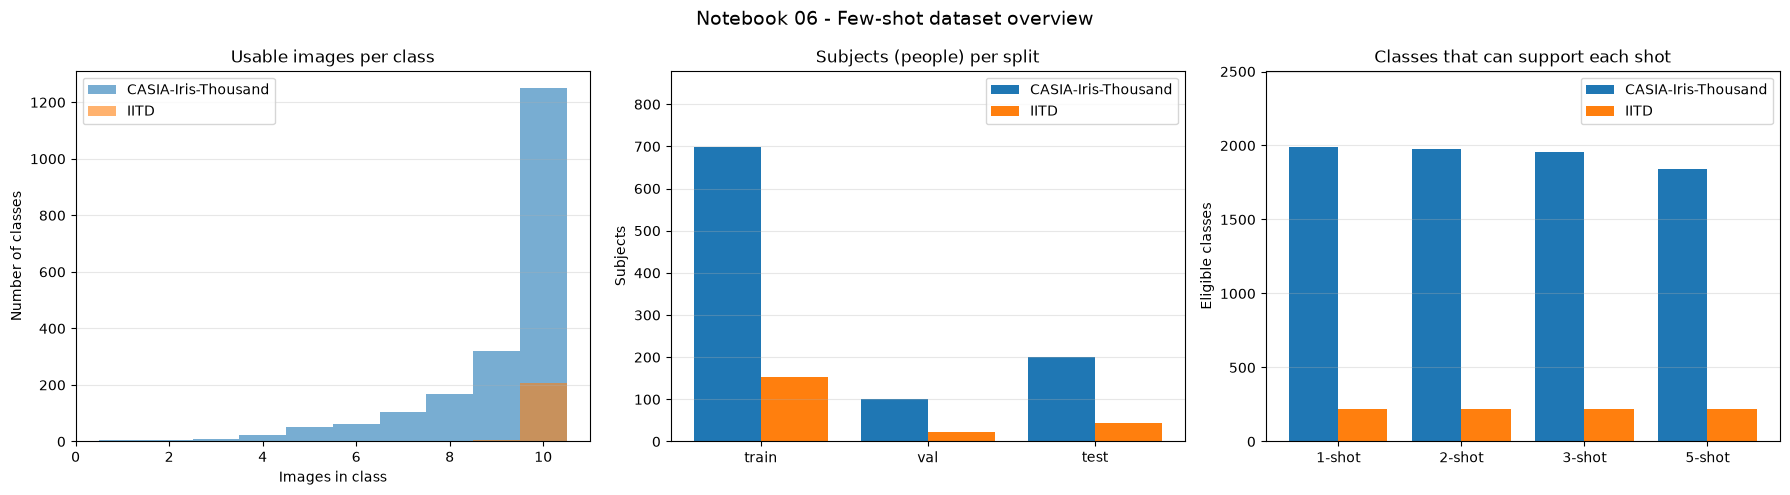

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset\fewshot_overview.png


In [16]:
# ============================================================
# 17. Overview plots
# ============================================================

datasets_present = sorted(class_table["dataset"].unique())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) usable images per class
max_images = int(class_table["n_usable_images"].max())
bins = np.arange(1, max_images + 2) - 0.5
for dataset_name in datasets_present:
    values = class_table.loc[class_table["dataset"] == dataset_name, "n_usable_images"]
    axes[0].hist(values, bins=bins, alpha=0.6, label=dataset_name)
axes[0].set_title("Usable images per class")
axes[0].set_xlabel("Images in class")
axes[0].set_ylabel("Number of classes")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# (b) subjects per split
width = 0.8 / max(len(datasets_present), 1)
positions = np.arange(len(SPLITS))
for i, dataset_name in enumerate(datasets_present):
    counts = [
        int(split_overview.loc[dataset_name, s]) if (dataset_name in split_overview.index and s in split_overview.columns) else 0
        for s in SPLITS
    ]
    axes[1].bar(positions + i * width, counts, width, label=dataset_name)
axes[1].set_xticks(positions + width * (len(datasets_present) - 1) / 2)
axes[1].set_xticklabels(SPLITS)
axes[1].set_title("Subjects (people) per split")
axes[1].set_ylabel("Subjects")
axes[1].set_ylim(0, axes[1].get_ylim()[1] * 1.2)   # headroom for the legend
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

# (c) eligible classes per shot
positions = np.arange(len(SHOTS))
for i, dataset_name in enumerate(datasets_present):
    counts = [
        int(eligibility_by_shot[(eligibility_by_shot["dataset"] == dataset_name)
                                & (eligibility_by_shot["shot"] == k)]["eligible_classes"].iloc[0])
        for k in SHOTS
    ]
    axes[2].bar(positions + i * width, counts, width, label=dataset_name)
axes[2].set_xticks(positions + width * (len(datasets_present) - 1) / 2)
axes[2].set_xticklabels([f"{k}-shot" for k in SHOTS])
axes[2].set_title("Classes that can support each shot")
axes[2].set_ylabel("Eligible classes")
axes[2].set_ylim(0, axes[2].get_ylim()[1] * 1.2)   # headroom for the legend
axes[2].legend()
axes[2].grid(axis="y", alpha=0.3)

plt.suptitle("Notebook 06 - Few-shot dataset overview", fontsize=14)
plt.tight_layout()

overview_path = RESULTS_DIR / "fewshot_overview.png"
plt.savefig(overview_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", overview_path)

## 18. Visual check: support vs. query

For a few classes per dataset and split, the support images (top) and a few query images (bottom) of the largest available shot are drawn. Support and query should look like the same iris, never like the same picture.


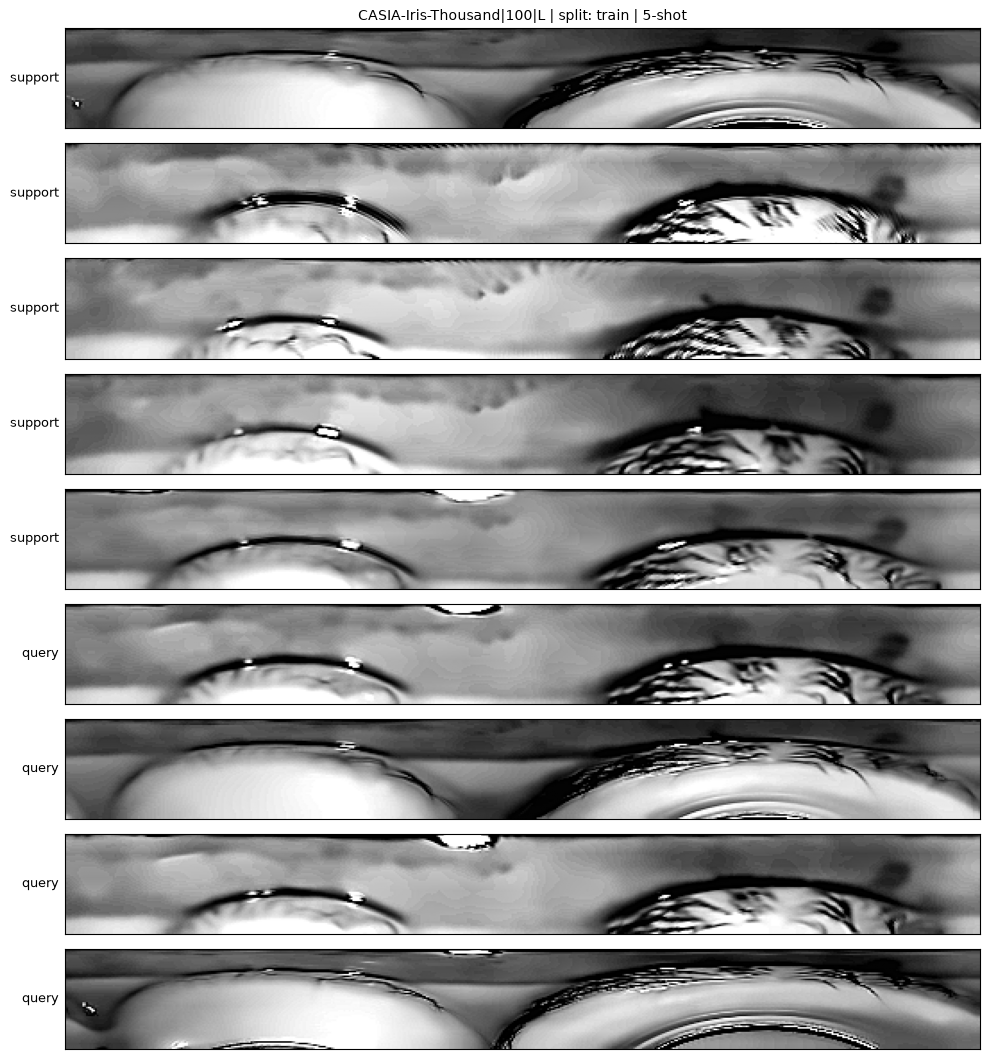

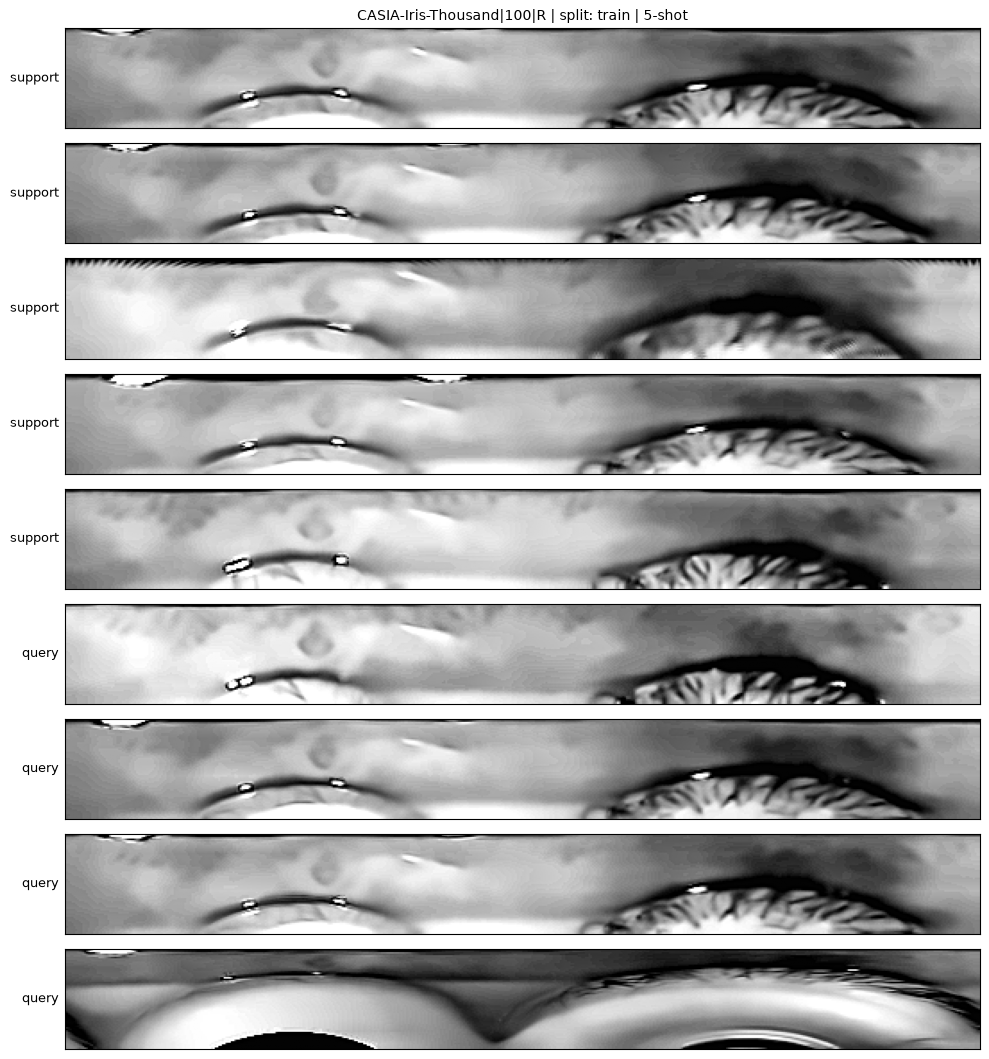

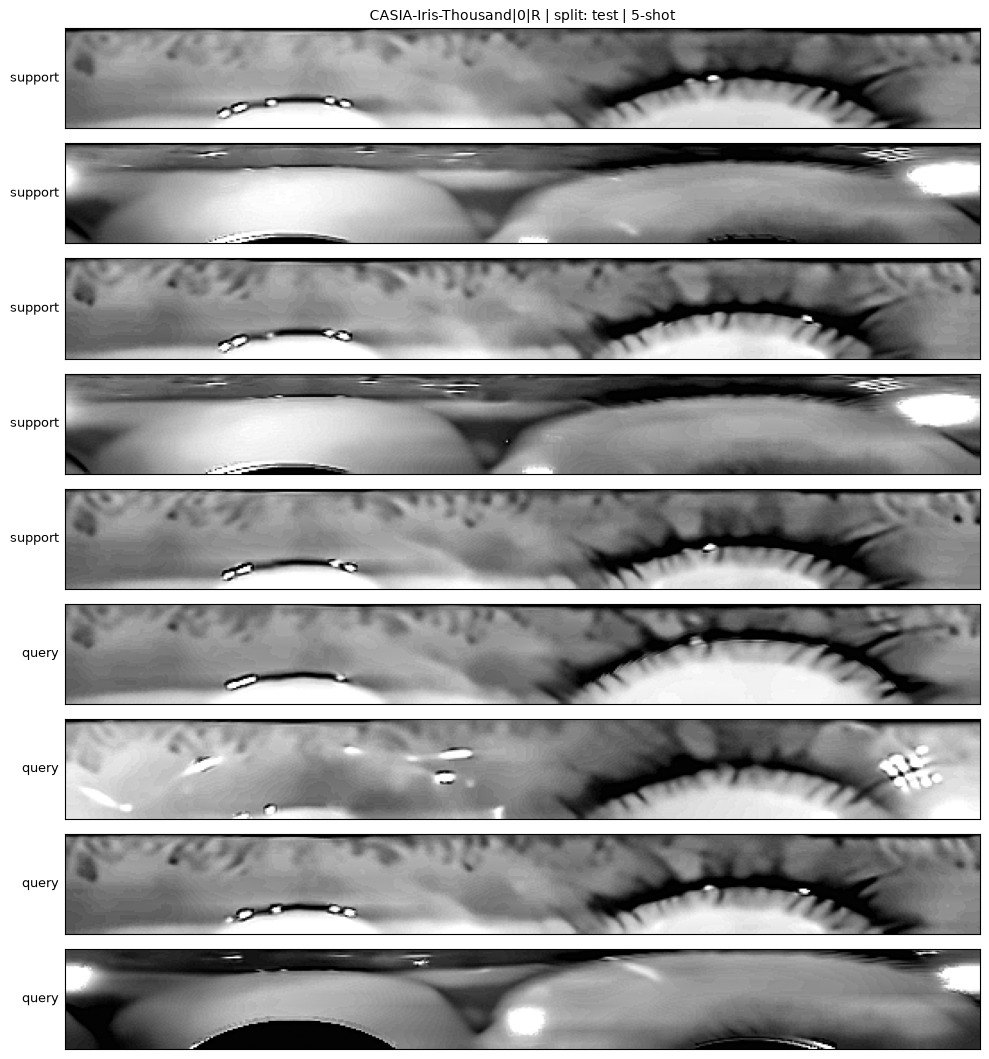

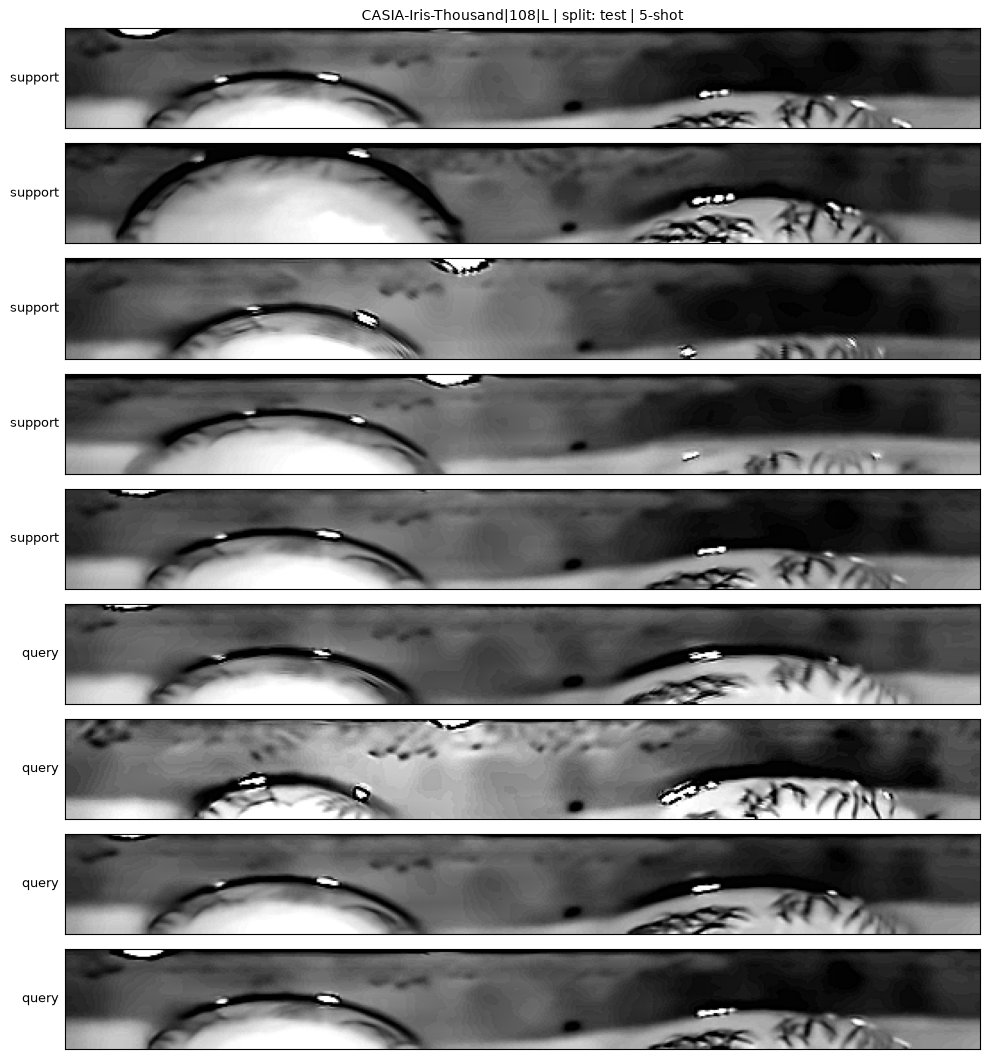

In [17]:
# ============================================================
# 18. Support vs. query previews
# ============================================================

def preview_class(class_id, shot, max_query_shown=4):
    group = long_manifest[(long_manifest["class_id"] == class_id) & (long_manifest["shot"] == shot)].copy()
    group["role_order"] = group["role"].map({"support": 0, "query": 1})
    group = group.sort_values(["role_order", "shuffle_rank"])

    support_rows = group[group["role"] == "support"]
    query_rows = group[group["role"] == "query"].head(max_query_shown)
    shown = pd.concat([support_rows, query_rows])

    fig, axes = plt.subplots(len(shown), 1, figsize=(10, 1.1 * len(shown) + 0.8))
    axes = np.atleast_1d(axes)

    for ax, (_, row) in zip(axes, shown.iterrows()):
        image = cv2.imread(str(row["source_path"]), cv2.IMREAD_GRAYSCALE)
        ax.imshow(image, cmap="gray", aspect="auto")
        ax.set_yticks([])
        ax.set_xticks([])
        ax.set_ylabel(row["role"], rotation=0, ha="right", va="center", fontsize=9)

    axes[0].set_title(f"{class_id} | split: {group['split'].iloc[0]} | {shot}-shot", fontsize=10)
    plt.tight_layout()

    output_path = (
        PREVIEW_DIR
        / f"{dataset_safe_name(group['dataset'].iloc[0])}_{group['split'].iloc[0]}_"
          f"{identity_safe_name(group['identity'].iloc[0])}_{eye_safe_name(group['eye'].iloc[0])}_{shot}shot.png"
    )
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    return fig, output_path


if SAVE_PREVIEWS:
    shown_inline = 0

    for dataset_name in datasets_present:
        for split in ["train", "test"]:
            subset = long_manifest[(long_manifest["dataset"] == dataset_name) & (long_manifest["split"] == split)]

            if subset.empty:
                continue

            shot = int(subset["shot"].max())
            class_ids = sorted(subset.loc[subset["shot"] == shot, "class_id"].unique())

            for class_id in class_ids[:NUM_PREVIEW_CLASSES]:
                fig, saved = preview_class(class_id, shot)
                if shown_inline < 4:
                    plt.show()
                    shown_inline += 1
                else:
                    plt.close(fig)

## 19. Final leakage report

Every check from before and after writing, saved as `leakage_report.csv`. This file is the evidence for the "no data leakage" requirement.


In [18]:
# ============================================================
# 19. Leakage report
# ============================================================

leakage_report = pd.DataFrame(leakage_checks)

display(leakage_report[["check", "passed", "critical", "details"]])

leakage_report.to_csv(RESULTS_DIR / "leakage_report.csv", index=False)
print("Saved:", RESULTS_DIR / "leakage_report.csv")

n_critical_failed = int(((~leakage_report["passed"]) & leakage_report["critical"]).sum())
n_warnings = int(((~leakage_report["passed"]) & (~leakage_report["critical"])).sum())

print(f"\nChecks run: {len(leakage_report)} | critical failures: {n_critical_failed} | warnings: {n_warnings}")

assert_no_critical_failures("final")

,check,passed,critical,details
0,subject sets are disjoint across train/val/test,True,True,"{'train&val': 0, 'train&test': 0, 'val&test': 0}"
1,class sets are disjoint across train/val/test,True,True,"{'train&val': 0, 'train&test': 0, 'val&test': 0}"
2,image sets are disjoint across train/val/test,True,True,"{'train&val': 0, 'train&test': 0, 'val&test': 0}"
3,every image_id appears exactly once,True,True,0 repeated
4,every source file is used by exactly one image,True,True,0 repeated
5,all images come from accepted (quality-passed)...,True,True,
6,all source files lie inside Notebook 05 good_i...,True,True,0 outside
7,no identical image content is shared across sp...,True,True,0 duplicated content hash(es) span more than o...
8,no identical image content is repeated inside ...,False,False,50 repeated
9,no identical image content appears under two d...,True,False,0 content hash(es) under several classes


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset\leakage_report.csv

Checks run: 44 | critical failures: 0 | warnings: 1


0

## 20. Final outputs

At the end of Notebook 06, the project should contain:

```text
results/fewshot_dataset/
├── 1shot/  2shot/  3shot/  5shot/
│   ├── train/{support,query}/<dataset>/<identity>_<eye>/*.png
│   ├── val/{support,query}/...
│   └── test/{support,query}/...
├── manifests/
│   ├── fewshot_manifest.csv
│   ├── fewshot_manifest_long.csv
│   ├── subject_split.csv
│   ├── class_table.csv
│   └── excluded.csv
├── previews/
├── split_config.json
├── fewshot_summary.csv
├── fewshot_overview.png
└── leakage_report.csv
```

A shot folder is missing if no class had enough usable images for that shot; the exclusion reasons are in `excluded.csv` and `class_table.csv`.


In [19]:
# ============================================================
# 20. Final output listing
# ============================================================

print("Notebook 06 output directory:")
print(RESULTS_DIR)

print("\nContents:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_dir():
        n_files = sum(1 for p in path.rglob("*") if p.is_file())
        print(f"- {path.name}/  ({n_files} files)")
    else:
        print(f"- {path.name}")

print("\nNotebook 06 completed.")

Notebook 06 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset

Contents:
- 1shot/  (11871 files)
- 2shot/  (14037 files)
- 3shot/  (16123 files)
- 5shot/  (19611 files)
- fewshot_overview.png
- fewshot_summary.csv
- leakage_report.csv
- manifests/  (5 files)
- previews/  (8 files)
- split_config.json

Notebook 06 completed.


## 21. What this notebook hands to Notebook 07 onward

```text
Notebook 05                 Notebook 06                      Notebook 07
Quality-filtered   --->     Few-shot dataset         --->    Baseline recognition
good_images/                (train / val / test,             (real data only)
                             1/2/3/5-shot)
```

### How each split must be used

| Split | Role | Allowed use |
|---|---|---|
| `train / support` | The only real images a model may learn from | Baseline training (07), latent model (08), generator training (09), final recognition training (13) |
| `train / query` | Held-out images of the **training** people | Closed-set diagnostics only. **Never** train on them. |
| `val / support + query` | Unseen people | Model selection and threshold tuning. Support = gallery or prototypes, query = probes. |
| `test / support + query` | Unseen people | **Final reporting only.** No training, tuning, or generator fitting may ever touch these. |

### Rules that keep the no-leakage guarantee intact downstream

1. **Synthetic images inherit the split of the identity they were generated for.** Synthetic images are produced only from `train / support`. Nothing from `val` or `test` may be used to train the latent model, the diffusion/StyleGAN generator, or the identity-verification model.
2. **Evaluation uses real images only**, exactly as the proposal specifies. Synthetic images never enter `val` or `test`.
3. **Compare shots fairly**: supports are nested (1 inside 2 inside 3 inside 5) and the query set of a class is the same at every shot.
4. **Cross-dataset evaluation (Notebook 14)**: train on the CASIA `train` split only, and evaluate on IITD. Never let the model see IITD during training for that experiment.
5. Load images through `manifests/fewshot_manifest_long.csv` (filter on `shot`, `split`, `role`) or through the `<K>shot/` folders. They are guaranteed to agree.
6. To get a different random draw, change `RANDOM_SEED` and re-run; the old `<K>shot/` folders are replaced and the new `leakage_report.csv` re-verifies the result. Record the seed (`split_config.json`) with every reported number.
